# Сводный отчёт: сравнение всех алгоритмов из лабораторных 1-5

В лабораторных 1-5 на одних и тех же датасетах и с одним и тем же протоколом
(фиксированный сплит train/test 80/20, random_state=42) исследовались:
1. KNN
2. логистическая + линейная регрессия
3. решающее дерево
4. случайный лес
5. градиентный бустинг

Для каждого алгоритма оценивались 4 варианта:
- бейзлайн - sklearn с дефолтными параметрами на сырых данных;
- улучшенный - sklearn после проверки гипотез (предобработка + подбор
  гиперпараметров);
- своя реализация - имплементация на numpy на данных бейзлайна;
- своя + улучшения - имплементация на numpy с техниками из улучшенного
  бейзлайна.

Здесь собираю все метрики (из results/labN_metrics.json), строю сводную
таблицу и графики и делаю итоговые выводы.

In [1]:
import os

for _root in [os.getcwd(), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(_root, "data")):
        ROOT = _root
        break

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

ALGOS = {
    1: "KNN",
    2: "Linear/Logistic",
    3: "Decision Tree",
    4: "Random Forest",
    5: "Gradient Boosting",
}
VARIANTS = {
    "baseline": "бейзлайн",
    "improved": "улучшенный",
    "custom": "своя реализация",
    "custom_improved": "своя + улучшения",
}

In [2]:
# загружаю метрики всех лаб
data = {}
for lab in ALGOS:
    path = os.path.join(ROOT, "results", f"lab{lab}_metrics.json")
    with open(path) as f:
        data[lab] = json.load(f)

def build_table(task):
    rows = []
    for lab, name in ALGOS.items():
        for var_key, var_name in VARIANTS.items():
            m = data[lab][task][var_key]
            rows.append({"алгоритм": name, "вариант": var_name, **m})
    return pd.DataFrame(rows)

table_c = build_table("classification")
table_r = build_table("regression")
print(f"Загружено: {len(table_c)} строк классификация, {len(table_r)} строк регрессия")

Загружено: 20 строк классификация, 20 строк регрессия


## 1. Классификация: Maternal Health Risk

Метрики: accuracy, macro-F1, ROC-AUC (ovr). Чем больше - тем лучше.

In [3]:
# сводная таблица по классификации
table_c.round(4)

,алгоритм,вариант,accuracy,f1_macro,roc_auc_ovr
0,KNN,бейзлайн,0.6798,0.6854,0.8653
1,KNN,улучшенный,0.8571,0.8646,0.9605
2,KNN,своя реализация,0.6798,0.6854,0.8604
3,KNN,своя + улучшения,0.8571,0.8646,0.9622
4,Linear/Logistic,бейзлайн,0.5961,0.5917,0.7612
5,Linear/Logistic,улучшенный,0.6798,0.6923,0.8400
6,Linear/Logistic,своя реализация,0.3448,0.2105,0.5961
7,Linear/Logistic,своя + улучшения,0.6749,0.6782,0.8349
8,Decision Tree,бейзлайн,0.8424,0.8518,0.9234
9,Decision Tree,улучшенный,0.8473,0.8558,0.9259


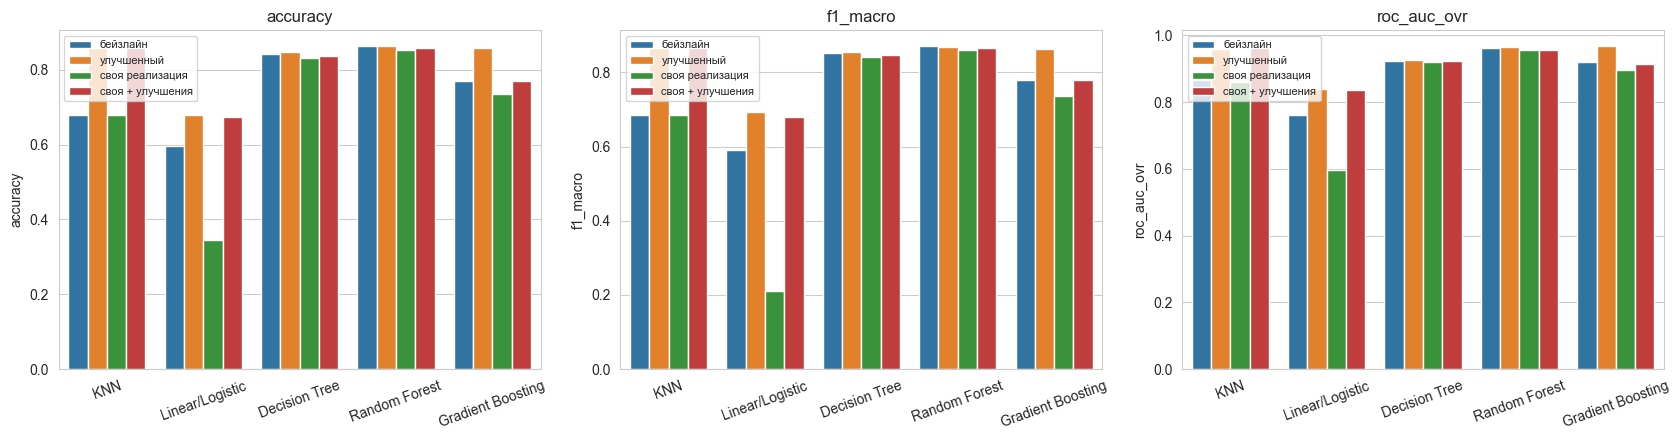

In [4]:
# графики: все метрики по алгоритмам и вариантам
metrics_c = ["accuracy", "f1_macro", "roc_auc_ovr"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, metrics_c):
    sns.barplot(data=table_c, x="алгоритм", y=metric, hue="вариант", ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
# таблица "лучший вариант каждого алгоритма" (улучшенный бейзлайн)
best_c = table_c[table_c["вариант"] == "улучшенный"].set_index("алгоритм")[metrics_c]
best_c.round(4)

,accuracy,f1_macro,roc_auc_ovr
алгоритм,,,
KNN,0.8571,0.8646,0.9605
Linear/Logistic,0.6798,0.6923,0.8400
Decision Tree,0.8473,0.8558,0.9259
Random Forest,0.8621,0.8696,0.9649
Gradient Boosting,0.8571,0.8634,0.9667


Наблюдения по классификации:
- лучший результат (accuracy ~0.86, ROC-AUC ~0.96) дают три алгоритма: KNN,
  случайный лес и подобранный градиентный бустинг. Одиночное дерево чуть
  позади (0.85), логистическая регрессия заметно отстаёт (0.68);
- KNN и лес хороши уже почти без настройки, а бустинг на дефолтных
  параметрах недообучается (0.77) и раскрывается только после подбора;
- логистической регрессии не хватает нелинейности: даже с полиномиальными
  признаками она не дотягивает до остальных - границы между классами сложнее;
- свои имплементации везде воспроизводят sklearn (максимальный разрыв - у
  бустинга, где мелкие отличия деревьев накапливаются от итерации к итерации).

## 2. Регрессия: CO2 Emission by Vehicles

Метрики: RMSE, MAE (меньше - лучше), R2 (больше - лучше).

In [6]:
# сводная таблица по регрессии
table_r.round(2)

,алгоритм,вариант,rmse,mae,r2
0,KNN,бейзлайн,10.46,4.10,0.97
1,KNN,улучшенный,6.09,2.33,0.99
2,KNN,своя реализация,10.44,4.08,0.97
3,KNN,своя + улучшения,6.46,2.37,0.99
4,Linear/Logistic,бейзлайн,18.37,11.53,0.90
5,Linear/Logistic,улучшенный,5.09,3.07,0.99
6,Linear/Logistic,своя реализация,18.37,11.53,0.90
7,Linear/Logistic,своя + улучшения,5.04,3.07,0.99
8,Decision Tree,бейзлайн,12.16,3.35,0.96
9,Decision Tree,улучшенный,3.56,2.05,1.00


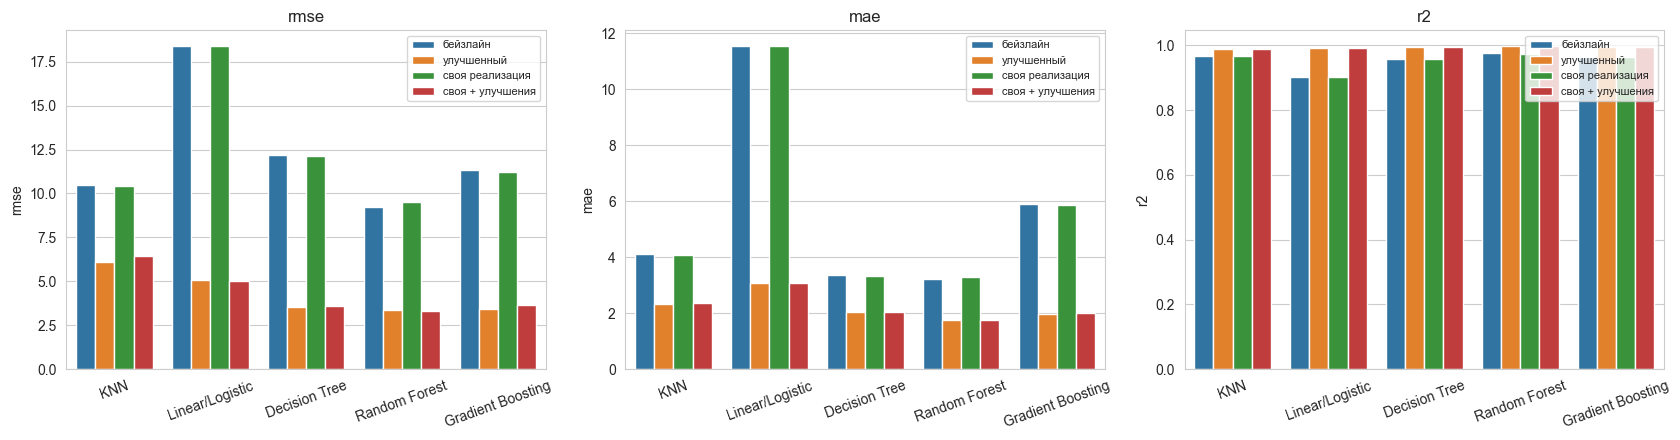

In [7]:
# графики: все метрики по алгоритмам и вариантам
metrics_r = ["rmse", "mae", "r2"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, metrics_r):
    sns.barplot(data=table_r, x="алгоритм", y=metric, hue="вариант", ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# таблица "лучший вариант каждого алгоритма" (улучшенный бейзлайн)
best_r = table_r[table_r["вариант"] == "улучшенный"].set_index("алгоритм")[metrics_r]
best_r.round(2)

,rmse,mae,r2
алгоритм,,,
KNN,6.09,2.33,0.99
Linear/Logistic,5.09,3.07,0.99
Decision Tree,3.56,2.05,1.00
Random Forest,3.33,1.74,1.00
Gradient Boosting,3.40,1.97,1.00


Наблюдения по регрессии:
- лучший результат (RMSE ~3.3) у градиентного бустинга и случайного леса;
- one-hot кодирование категориальных признаков (марка, класс, коробка,
  топливо) дало огромный прирост всем моделям, кроме KNN: линейная регрессия
  18.4 -> 5.1, дерево 12.2 -> 3.6, лес 9.2 -> 3.3, бустинг 11.3 -> 3.4;
- KNN единственный, кому one-hot повредил: разреженные бинарные признаки
  искажают расстояния. Его лучший результат (6.1) - на числовых признаках с
  масштабированием и подобранным k;
- связь выбросов CO2 с характеристиками автомобиля в основном линейная и
  гладкая, поэтому модели, хорошо интерполирующие (ансамбли, линейная с
  one-hot), обгоняют "память" KNN.

## 3. Что дала предобработка (сводно по гипотезам всех лаб)

In [9]:
# сводная таблица по гипотезам: что сработало, а что нет
hyp = pd.DataFrame([
    {"приём": "масштабирование", "KNN": "да (критично)", "Linear/Logistic": "да (критично)",
     "Tree": "нет (не нужно)", "Forest": "нет (не нужно)", "Boosting": "нет (не нужно)"},
    {"приём": "one-hot категориальных", "KNN": "нет (вредит)", "Linear/Logistic": "да (огромный)",
     "Tree": "да (огромный)", "Forest": "да (огромный)", "Boosting": "да (большой)"},
    {"приём": "дедупликация", "KNN": "нет", "Linear/Logistic": "не проверялась",
     "Tree": "не проверялась", "Forest": "не проверялась", "Boosting": "не проверялась"},
    {"приём": "удаление выбросов (HeartRate=7)", "KNN": "да (слабо)", "Linear/Logistic": "да (слабо)",
     "Tree": "да (слабо)", "Forest": "да (слабо)", "Boosting": "да (слабо)"},
    {"приём": "новые признаки", "KNN": "нет", "Linear/Logistic": "да (полиномы)",
     "Tree": "-", "Forest": "-", "Boosting": "-"},
    {"приём": "подбор гиперпараметров", "KNN": "да (большой)", "Linear/Logistic": "да (умеренный)",
     "Tree": "да (умеренный)", "Forest": "да (слабый)", "Boosting": "да (большой)"},
])
hyp

,приём,KNN,Linear/Logistic,Tree,Forest,Boosting
0,масштабирование,да (критично),да (критично),нет (не нужно),нет (не нужно),нет (не нужно)
1,one-hot категориальных,нет (вредит),да (огромный),да (огромный),да (огромный),да (большой)
2,дедупликация,нет,не проверялась,не проверялась,не проверялась,не проверялась
3,удаление выбросов (HeartRate=7),да (слабо),да (слабо),да (слабо),да (слабо),да (слабо)
4,новые признаки,нет,да (полиномы),-,-,-
5,подбор гиперпараметров,да (большой),да (умеренный),да (умеренный),да (слабый),да (большой)


Главный вывод по предобработке: она зависит от алгоритма, универсальных
рецептов нет. Масштабирование обязательно для методов на расстояниях и
градиентах, но бесполезно деревьям. One-hot помогает всем, кроме KNN.
Подбор гиперпараметров важнее всего для KNN и бустинга, а лес почти не
чувствителен к настройкам.

## 4. Итоговые выводы

1. На задаче классификации (триаж риска по показателям беременных) лучшие
   результаты показали KNN, случайный лес и градиентный бустинг после
   настройки (accuracy ~0.86, ROC-AUC ~0.96). Данные хорошо описываются
   локальной структурой ("похожие пациенты - похожий риск"), поэтому метод
   ближайших соседей здесь неожиданно силён.
2. На задаче регрессии (выбросы CO2 по характеристикам авто) выиграли
   ансамбли (бустинг RMSE 3.40, лес 3.33). Связь гладкая и близкая к линейной,
   категориальные признаки дают большой вклад через one-hot.
3. Порядок чувствительности к гиперпараметрам: бустинг и KNN - высокая,
   дерево и линейные модели - средняя, лес - низкая.
4. Собственные имплементации на numpy (KNN, линейная/логистическая регрессия,
   дерево, лес, бустинг) во всех лабораторных воспроизвели результаты sklearn
   с точностью до мелких деталей, что подтверждает корректность понимания
   алгоритмов.
5. Протокол честного сравнения (фиксированный тестовый сплит, все улучшения
   только на train) позволил сравнивать все 5 лабораторных между собой
   напрямую - таблицы выше.